In [1]:

%pip install -q pyspark

In [4]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.getOrCreate()

print("Spark iniciado correctamente")
print("Version:", spark.version)

Spark iniciado correctamente
Version: 4.0.5


In [5]:
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
RDD_Cliente = spark.sparkContext.textFile(
    "/content/drive/MyDrive/Veterinaria_BigData/CLIENTE.csv"
)

RDD_Cliente.take(5)

['id_cliente;nombre;apellido;telefono;email;direccion',
 '1;Carlos;Mendoza;987654321;carlos.mendoza@gmail.com;Av. Los Pinos 123, Lima',
 '2;Lucía;Ramírez;976543210;lucia.ramirez@gmail.com;Jr. Las Flores 456, Lima',
 '3;Jorge;Torres;965432109;jorge.torres@gmail.com;Calle Real 789, Lima',
 '4;Ana;Vargas;954321098;ana.vargas@gmail.com;Av. Colonial 321, Lima']

In [7]:
cabecera = RDD_Cliente.first()

RDD_Cliente1 = RDD_Cliente.filter(
    lambda dato: dato != cabecera
)

RDD_Cliente1.take(5)

['1;Carlos;Mendoza;987654321;carlos.mendoza@gmail.com;Av. Los Pinos 123, Lima',
 '2;Lucía;Ramírez;976543210;lucia.ramirez@gmail.com;Jr. Las Flores 456, Lima',
 '3;Jorge;Torres;965432109;jorge.torres@gmail.com;Calle Real 789, Lima',
 '4;Ana;Vargas;954321098;ana.vargas@gmail.com;Av. Colonial 321, Lima',
 '5;Miguel;Quispe;943210987;miguel.quispe@gmail.com;Jr. Tacna 654, Lima']

In [8]:
total_clientes = RDD_Cliente1.count()

print("TOTAL DE CLIENTES:", total_clientes)

TOTAL DE CLIENTES: 12


In [9]:
ruta = "/content/drive/MyDrive/Veterinaria_BigData/"

tablas = [
    "CLIENTE",
    "MASCOTA",
    "VETERINARIO",
    "CITA",
    "HISTORIA_CLINICA",
    "TRATAMIENTO",
    "VACUNA",
    "PAGO"
]

RDD_Tablas = {}

for tabla in tablas:
    RDD_Tablas[tabla] = spark.sparkContext.textFile(
        ruta + tabla + ".csv"
    )

    print(tabla, ":", RDD_Tablas[tabla].count() - 1)

CLIENTE : 12
MASCOTA : 15
VETERINARIO : 3
CITA : 42
HISTORIA_CLINICA : 41
TRATAMIENTO : 28
VACUNA : 20
PAGO : 41


In [10]:
RDD_Cita = RDD_Tablas["CITA"]

print("ENCABEZADO:")
print(RDD_Cita.first())

print("\nPRIMEROS REGISTROS:")
for fila in RDD_Cita.take(4):
    print(fila)

ENCABEZADO:
id_cita;id_mascota;id_veterinario;fecha_hora;motivo;estado

PRIMEROS REGISTROS:
id_cita;id_mascota;id_veterinario;fecha_hora;motivo;estado
1;1;1;2024-10-01 09:00:00.000;Control general;Atendida
2;2;3;2024-10-05 10:30:00.000;Problemas de piel;Atendida
3;3;1;2024-10-08 11:00:00.000;Revisión de cadera;Atendida


In [11]:
import csv

cabecera_cita = RDD_Cita.first()

RDD_Cita1 = RDD_Cita.filter(lambda fila: fila != cabecera_cita)
RDD_Cita2 = RDD_Cita1.map(lambda fila: next(csv.reader([fila], delimiter=";")))

print("TOTAL DE CITAS:", RDD_Cita2.count())

for fila in RDD_Cita2.take(5): print(fila)

TOTAL DE CITAS: 42
['1', '1', '1', '2024-10-01 09:00:00.000', 'Control general', 'Atendida']
['2', '2', '3', '2024-10-05 10:30:00.000', 'Problemas de piel', 'Atendida']
['3', '3', '1', '2024-10-08 11:00:00.000', 'Revisión de cadera', 'Atendida']
['4', '4', '2', '2024-10-12 09:30:00.000', 'Cirugía de esterilización', 'Atendida']
['5', '5', '1', '2024-10-15 08:00:00.000', 'Vacunación anual', 'Atendida']


In [12]:
columnas_cita = next(csv.reader([cabecera_cita], delimiter=";"))

posicion_estado = [columna.strip().lower()
    for columna in columnas_cita].index("estado")

RDD_Estados = RDD_Cita2.map(lambda fila: (fila[posicion_estado], 1))

RDD_Resultado_Estados = RDD_Estados.reduceByKey(lambda a, b: a + b)

for estado, cantidad in sorted(RDD_Resultado_Estados.collect()):
    print(estado, ":", cantidad)


Atendida : 41
Pendiente : 1


In [13]:
RDD_Pago = RDD_Tablas["PAGO"]

print("ENCABEZADO:")
print(RDD_Pago.first())

print("\nPRIMEROS REGISTROS:")
for fila in RDD_Pago.take(4):
    print(fila)

ENCABEZADO:
id_pago;id_cita;monto;metodo_pago;fecha_pago;estado

PRIMEROS REGISTROS:
id_pago;id_cita;monto;metodo_pago;fecha_pago;estado
1;1;80.00;Efectivo;2024-10-01;Pagado
2;2;120.00;Tarjeta;2024-10-05;Pagado
3;3;90.00;Transferencia;2024-10-08;Pagado


In [14]:
cabecera_pago = RDD_Pago.first()

RDD_Pago1 = RDD_Pago.filter(lambda fila: fila != cabecera_pago)

RDD_Pago2 = RDD_Pago1.map(lambda fila: next(csv.reader([fila], delimiter=";")))

print("TOTAL DE PAGOS:", RDD_Pago2.count())

for fila in RDD_Pago2.take(5):
    print(fila)

TOTAL DE PAGOS: 41
['1', '1', '80.00', 'Efectivo', '2024-10-01', 'Pagado']
['2', '2', '120.00', 'Tarjeta', '2024-10-05', 'Pagado']
['3', '3', '90.00', 'Transferencia', '2024-10-08', 'Pagado']
['4', '4', '350.00', 'Tarjeta', '2024-10-12', 'Pagado']
['5', '5', '75.00', 'Efectivo', '2024-10-15', 'Pagado']


In [15]:
columnas_pago = [columna.strip().lower()
    for columna in next(csv.reader([cabecera_pago], delimiter=";"))]

pos_metodo = columnas_pago.index("metodo_pago")
pos_monto = columnas_pago.index("monto")

RDD_Ingresos = RDD_Pago2.map(lambda fila: (fila[pos_metodo],(1, float(fila[pos_monto]))))

RDD_Resultado_Ingresos = RDD_Ingresos.reduceByKey(lambda a, b: (a[0] + b[0],a[1] + b[1]))

print("INGRESOS POR METODO DE PAGO")

for metodo, valores in sorted(RDD_Resultado_Ingresos.collect()):
    print(metodo,"- PAGOS:", valores[0],"- INGRESOS: S/", round(valores[1], 2))

INGRESOS POR METODO DE PAGO
Efectivo - PAGOS: 14 - INGRESOS: S/ 1235.0
Tarjeta - PAGOS: 16 - INGRESOS: S/ 1955.0
Transferencia - PAGOS: 11 - INGRESOS: S/ 1100.0


In [16]:
total_pagos = RDD_Pago2.count()
total_ingresos = RDD_Pago2.map(lambda fila: float(fila[pos_monto])).sum()

print("TOTAL DE PAGOS:", total_pagos)
print("INGRESOS TOTALES: S/", round(total_ingresos, 2))

TOTAL DE PAGOS: 41
INGRESOS TOTALES: S/ 4290.0


In [17]:
RDD_Mascota = RDD_Tablas["MASCOTA"]

print("ENCABEZADO:")
print(RDD_Mascota.first())

print("\nPRIMEROS REGISTROS:")
for fila in RDD_Mascota.take(4):
    print(fila)

ENCABEZADO:
id_mascota;id_cliente;nombre;especie;raza;fecha_nacimiento;sexo

PRIMEROS REGISTROS:
id_mascota;id_cliente;nombre;especie;raza;fecha_nacimiento;sexo
1;1;Max;Perro;Labrador;2020-03-15;Macho
2;1;Luna;Gato;Siamés;2021-07-20;Hembra
3;2;Rocky;Perro;Pastor Alemán;2019-11-10;Macho


In [18]:
cabecera_mascota = RDD_Mascota.first()

RDD_Mascota1 = RDD_Mascota.filter(lambda fila: fila != cabecera_mascota)
RDD_Mascota2 = RDD_Mascota1.map(lambda fila: next(csv.reader([fila], delimiter=";")))

print("TOTAL DE MASCOTAS:", RDD_Mascota2.count())

for fila in RDD_Mascota2.take(5):
    print(fila)

TOTAL DE MASCOTAS: 15
['1', '1', 'Max', 'Perro', 'Labrador', '2020-03-15', 'Macho']
['2', '1', 'Luna', 'Gato', 'Siamés', '2021-07-20', 'Hembra']
['3', '2', 'Rocky', 'Perro', 'Pastor Alemán', '2019-11-10', 'Macho']
['4', '3', 'Mia', 'Gato', 'Persa', '2022-01-05', 'Hembra']
['5', '4', 'Toby', 'Perro', 'Beagle', '2020-08-25', 'Macho']


In [20]:
columnas_mascota = [columna.strip().lower()
    for columna in next(csv.reader([cabecera_mascota], delimiter=";"))]

pos_especie = columnas_mascota.index("especie")

RDD_Especies = RDD_Mascota2.map(lambda fila: (fila[pos_especie], 1))
RDD_Resultado_Especies = RDD_Especies.reduceByKey(lambda a, b: a + b)

print("CANTIDAD DE MASCOTAS POR ESPECIE")
for especie, cantidad in sorted(RDD_Resultado_Especies.collect()):
    print(especie, ":", cantidad)

CANTIDAD DE MASCOTAS POR ESPECIE
Gato : 5
Perro : 10


In [21]:
RDD_Veterinario = RDD_Tablas["VETERINARIO"]
cabecera_veterinario = RDD_Veterinario.first()

RDD_Veterinario1 = RDD_Veterinario.filter(lambda fila: fila != cabecera_veterinario)
RDD_Veterinario2 = RDD_Veterinario1.map(lambda fila: next(csv.reader([fila], delimiter=";")))

columnas_veterinario = [columna.strip().lower()
    for columna in next(csv.reader([cabecera_veterinario], delimiter=";"))]

print("TOTAL DE VETERINARIOS:", RDD_Veterinario2.count())
print("COLUMNAS:", columnas_veterinario)

for fila in RDD_Veterinario2.take(3):
    print(fila)

TOTAL DE VETERINARIOS: 3
COLUMNAS: ['id_veterinario', 'nombre', 'apellido', 'especialidad', 'telefono']
['1', 'Roberto', 'Salinas', 'Medicina general', '911111111']
['2', 'Patricia', 'León', 'Cirugía veterinaria', '922222222']
['3', 'Eduardo', 'Chávez', 'Dermatología animal', '933333333']


In [22]:
pos_id_vet = columnas_veterinario.index("id_veterinario")
pos_nombre_vet = columnas_veterinario.index("nombre")
pos_apellido_vet = columnas_veterinario.index("apellido")

pos_vet_cita = [columna.strip().lower()
    for columna in columnas_cita].index("id_veterinario")

RDD_Nombres_Vet = RDD_Veterinario2.map(lambda fila: (fila[pos_id_vet],fila[pos_nombre_vet] + " " + fila[pos_apellido_vet]))
RDD_Citas_Vet = RDD_Cita2.map(lambda fila: (fila[pos_vet_cita], 1)).reduceByKey(lambda a, b: a + b)
RDD_Resultado_Vet = RDD_Nombres_Vet.join(RDD_Citas_Vet)

print("CITAS POR VETERINARIO")

for identificador, datos_vet in sorted(RDD_Resultado_Vet.collect()):
    print(datos_vet[0],"- CITAS:",datos_vet[1])

CITAS POR VETERINARIO
Roberto Salinas - CITAS: 21
Patricia León - CITAS: 10
Eduardo Chávez - CITAS: 11


In [23]:
#experimentando con los datos

In [24]:
import time
import statistics

print("HERRAMIENTAS PARA EXPERIMENTOS CARGADAS")
print("VERSION DE SPARK:", spark.version)

HERRAMIENTAS PARA EXPERIMENTOS CARGADAS
VERSION DE SPARK: 4.0.5


In [25]:
RDD_Original = RDD_Cita2.cache()

total_original = RDD_Original.count()
print("EXPERIMENTO 1: DATOS ORIGINALES")
print("TOTAL DE REGISTROS:", total_original)
print("PARTICIONES:", RDD_Original.getNumPartitions())

EXPERIMENTO 1: DATOS ORIGINALES
TOTAL DE REGISTROS: 42
PARTICIONES: 2


In [26]:
pos_estado = [columna.strip().lower()
    for columna in columnas_cita].index("estado")

tiempos_original = []

for prueba in range(1, 6):

    inicio = time.perf_counter()
    resultado = (RDD_Original.map(lambda fila: (fila[pos_estado], 1)).reduceByKey(lambda a, b: a + b).collect())

    fin = time.perf_counter()

    tiempo_ms = (fin - inicio) * 1000
    tiempos_original.append(tiempo_ms)
    print("PRUEBA:", prueba,"| TIEMPO_MS:", round(tiempo_ms, 2))

print("\nRESULTADOS DEL EXPERIMENTO 1")
print("REGISTROS:", total_original)
print("PROMEDIO_MS:", round(statistics.mean(tiempos_original), 2))
print("MINIMO_MS:", round(min(tiempos_original), 2))
print("MAXIMO_MS:", round(max(tiempos_original), 2))
print("RESULTADO:", sorted(resultado))

PRUEBA: 1 | TIEMPO_MS: 405.48
PRUEBA: 2 | TIEMPO_MS: 296.68
PRUEBA: 3 | TIEMPO_MS: 245.49
PRUEBA: 4 | TIEMPO_MS: 293.44
PRUEBA: 5 | TIEMPO_MS: 308.54

RESULTADOS DEL EXPERIMENTO 1
REGISTROS: 42
PROMEDIO_MS: 309.93
MINIMO_MS: 245.49
MAXIMO_MS: 405.48
RESULTADO: [('Atendida', 41), ('Pendiente', 1)]


In [27]:
# aumentar el volumen de datos
RDD_420 = (RDD_Original.flatMap(lambda fila: [fila] * 10).cache())
RDD_4200 = (RDD_Original.flatMap(lambda fila: [fila] * 100).cache())

total_420 = RDD_420.count()
total_4200 = RDD_4200.count()

print("ESCENARIOS DE PRUEBA")
print("ORIGINAL:", total_original)
print("AMPLIADO X10:", total_420)
print("AMPLIADO X100:", total_4200)

ESCENARIOS DE PRUEBA
ORIGINAL: 42
AMPLIADO X10: 420
AMPLIADO X100: 4200


In [28]:
# comparando rendimiento
escenarios = [("ORIGINAL", RDD_Original),("AMPLIADO X10", RDD_420),("AMPLIADO X100", RDD_4200)]
resultados_experimentos = []

for nombre, rdd in escenarios:
    tiempos = []
    for prueba in range(1, 6):
        inicio = time.perf_counter()

        resultado = (rdd.map(lambda fila: (fila[pos_estado], 1)).reduceByKey(lambda a, b: a + b).collect())

        fin = time.perf_counter()
        tiempo_ms = (fin - inicio) * 1000
        tiempos.append(tiempo_ms)

    registros = rdd.count()
    promedio = statistics.mean(tiempos)
    resultados_experimentos.append((nombre, registros, promedio, min(tiempos), max(tiempos)))

    print("\nESCENARIO:", nombre)
    print("REGISTROS:", registros)
    print("PROMEDIO_MS:", round(promedio, 2))
    print("MINIMO_MS:", round(min(tiempos), 2))
    print("MAXIMO_MS:", round(max(tiempos), 2))
    print("RESULTADO:", sorted(resultado))


ESCENARIO: ORIGINAL
REGISTROS: 42
PROMEDIO_MS: 291.07
MINIMO_MS: 252.81
MAXIMO_MS: 365.17
RESULTADO: [('Atendida', 41), ('Pendiente', 1)]

ESCENARIO: AMPLIADO X10
REGISTROS: 420
PROMEDIO_MS: 278.91
MINIMO_MS: 244.39
MAXIMO_MS: 357.12
RESULTADO: [('Atendida', 410), ('Pendiente', 10)]

ESCENARIO: AMPLIADO X100
REGISTROS: 4200
PROMEDIO_MS: 239.46
MINIMO_MS: 225.49
MAXIMO_MS: 255.28
RESULTADO: [('Atendida', 4100), ('Pendiente', 100)]


In [29]:
#comparando resultados
print("COMPARACION DE RENDIMIENTO DE PYSPARK")
print("-" * 75)
print(
    f"{'ESCENARIO':<18}"
    f"{'REGISTROS':<15}"
    f"{'PROMEDIO MS':<15}"
    f"{'MINIMO MS':<13}"
    f"{'MAXIMO MS':<13}"
)

for nombre, registros, promedio, minimo, maximo in resultados_experimentos:
    print(
        f"{nombre:<18}"
        f"{registros:<15}"
        f"{promedio:<15.2f}"
        f"{minimo:<13.2f}"
        f"{maximo:<13.2f}"
    )

COMPARACION DE RENDIMIENTO DE PYSPARK
---------------------------------------------------------------------------
ESCENARIO         REGISTROS      PROMEDIO MS    MINIMO MS    MAXIMO MS    
ORIGINAL          42             291.07         252.81       365.17       
AMPLIADO X10      420            278.91         244.39       357.12       
AMPLIADO X100     4200           239.46         225.49       255.28       


In [30]:
# CREAR ESCENARIOS AMPLIADOS
RDD_42000 = RDD_Original.flatMap(lambda fila: [fila] * 1000).cache()
RDD_420000 = RDD_Original.flatMap(lambda fila: [fila] * 10000).cache()

print("ESCENARIOS AMPLIADOS")
print("42,000 REGISTROS:", RDD_42000.count())
print("420,000 REGISTROS:", RDD_420000.count())

ESCENARIOS AMPLIADOS
42,000 REGISTROS: 42000
420,000 REGISTROS: 420000


In [32]:
#Medicion del rendimiento
import time
import statistics

escenarios_nuevos = [
    ("42 REGISTROS", RDD_Original),
    ("420 REGISTROS", RDD_420),
    ("4200 REGISTROS", RDD_4200),
    ("42000 REGISTROS", RDD_42000),
    ("420000 REGISTROS", RDD_420000)
]

mediciones = {nombre: [] for nombre, rdd in escenarios_nuevos}
conteos = {}

for repeticion in range(5):
    orden = escenarios_nuevos if repeticion % 2 == 0 else escenarios_nuevos[::-1]
    for nombre, rdd in orden:
        inicio = time.perf_counter()
        resultado = (rdd.map(lambda fila: (fila[pos_estado], 1)).reduceByKey(lambda a, b: a + b).collect())

        tiempo_ms = (time.perf_counter() - inicio) * 1000
        mediciones[nombre].append(tiempo_ms)
        conteos[nombre] = dict(resultado)

        print("REPETICION:", repeticion + 1, "| ESCENARIO:", nombre,"| TIEMPO_MS:", round(tiempo_ms, 2))

REPETICION: 1 | ESCENARIO: 42 REGISTROS | TIEMPO_MS: 203.56
REPETICION: 1 | ESCENARIO: 420 REGISTROS | TIEMPO_MS: 206.84
REPETICION: 1 | ESCENARIO: 4200 REGISTROS | TIEMPO_MS: 198.93
REPETICION: 1 | ESCENARIO: 42000 REGISTROS | TIEMPO_MS: 229.11
REPETICION: 1 | ESCENARIO: 420000 REGISTROS | TIEMPO_MS: 622.2
REPETICION: 2 | ESCENARIO: 420000 REGISTROS | TIEMPO_MS: 409.93
REPETICION: 2 | ESCENARIO: 42000 REGISTROS | TIEMPO_MS: 259.31
REPETICION: 2 | ESCENARIO: 4200 REGISTROS | TIEMPO_MS: 186.83
REPETICION: 2 | ESCENARIO: 420 REGISTROS | TIEMPO_MS: 199.3
REPETICION: 2 | ESCENARIO: 42 REGISTROS | TIEMPO_MS: 228.93
REPETICION: 3 | ESCENARIO: 42 REGISTROS | TIEMPO_MS: 218.36
REPETICION: 3 | ESCENARIO: 420 REGISTROS | TIEMPO_MS: 254.06
REPETICION: 3 | ESCENARIO: 4200 REGISTROS | TIEMPO_MS: 233.43
REPETICION: 3 | ESCENARIO: 42000 REGISTROS | TIEMPO_MS: 274.49
REPETICION: 3 | ESCENARIO: 420000 REGISTROS | TIEMPO_MS: 559.03
REPETICION: 4 | ESCENARIO: 420000 REGISTROS | TIEMPO_MS: 458.26
REPETICI

In [33]:
#comparacion
print("RESULTADOS FINALES DE ESCALABILIDAD")
print("-" * 75)

for nombre, rdd in escenarios_nuevos:
    tiempos = mediciones[nombre]

    print("\nESCENARIO:", nombre)
    print("PROMEDIO_MS:", round(statistics.mean(tiempos), 2))
    print("MINIMO_MS:", round(min(tiempos), 2))
    print("MAXIMO_MS:", round(max(tiempos), 2))
    print("RESULTADO:", conteos[nombre])

RESULTADOS FINALES DE ESCALABILIDAD
---------------------------------------------------------------------------

ESCENARIO: 42 REGISTROS
PROMEDIO_MS: 220.61
MINIMO_MS: 203.56
MAXIMO_MS: 245.28
RESULTADO: {'Atendida': 41, 'Pendiente': 1}

ESCENARIO: 420 REGISTROS
PROMEDIO_MS: 218.75
MINIMO_MS: 199.3
MAXIMO_MS: 254.06
RESULTADO: {'Atendida': 410, 'Pendiente': 10}

ESCENARIO: 4200 REGISTROS
PROMEDIO_MS: 209.94
MINIMO_MS: 186.83
MAXIMO_MS: 233.43
RESULTADO: {'Atendida': 4100, 'Pendiente': 100}

ESCENARIO: 42000 REGISTROS
PROMEDIO_MS: 247.2
MINIMO_MS: 226.16
MAXIMO_MS: 274.49
RESULTADO: {'Atendida': 41000, 'Pendiente': 1000}

ESCENARIO: 420000 REGISTROS
PROMEDIO_MS: 515.56
MINIMO_MS: 409.93
MAXIMO_MS: 622.2
RESULTADO: {'Atendida': 410000, 'Pendiente': 10000}


In [34]:
#tabla de resultados
import pandas as pd
datos = []

for nombre, rdd in escenarios_nuevos:
    tiempos = mediciones[nombre]

    datos.append({
        "ESCENARIO": nombre,
        "REGISTROS": rdd.count(),
        "PROMEDIO_MS": round(statistics.mean(tiempos), 2),
        "MINIMO_MS": round(min(tiempos), 2),
        "MAXIMO_MS": round(max(tiempos), 2)
    })

df_resultados = pd.DataFrame(datos)
display(df_resultados)

,ESCENARIO,REGISTROS,PROMEDIO_MS,MINIMO_MS,MAXIMO_MS
0,42 REGISTROS,42,220.61,203.56,245.28
1,420 REGISTROS,420,218.75,199.30,254.06
2,4200 REGISTROS,4200,209.94,186.83,233.43
3,42000 REGISTROS,42000,247.20,226.16,274.49
4,420000 REGISTROS,420000,515.56,409.93,622.20


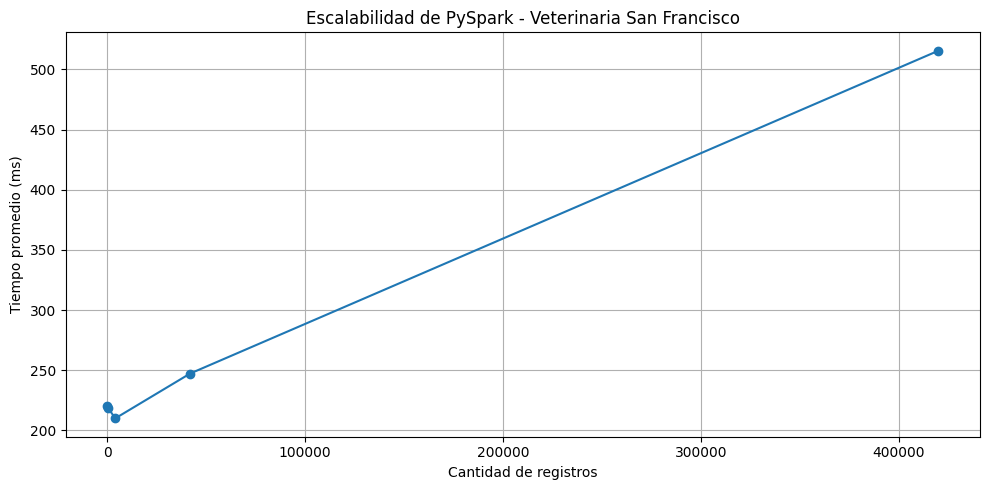

In [35]:
#gráfica de escalabilidad
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df_resultados["REGISTROS"],df_resultados["PROMEDIO_MS"],marker="o")

plt.title("Escalabilidad de PySpark - Veterinaria San Francisco")
plt.xlabel("Cantidad de registros")
plt.ylabel("Tiempo promedio (ms)")
plt.grid(True)

plt.tight_layout()
plt.savefig("/content/grafica_escalabilidad.png",dpi=300,bbox_inches="tight")
plt.show()

In [36]:
#Guardando resultados
df_resultados.to_csv("/content/resultados_escalabilidad.csv",index=False,encoding="utf-8-sig")
print("CSV guardado correctamente")

CSV guardado correctamente


In [37]:
from google.colab import files
files.download("/content/resultados_escalabilidad.csv")
files.download("/content/grafica_escalabilidad.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>